# 14. Feature groups: the pre-registered test and its result

**Question.** Which groups of inputs (recent history, calendar, segment history, market and specialty context, competitor volumes, outside signals, data-quality flags) add anything beyond a small base set when predicting next month's Zilretta share, for segments (T2) and for the national series (T1)?

**Answer in one line.** Only specialty and market context (G4) earns its place for segments, at about 0.06% of log-loss and robust to removing COVID and the 2024 dip; no group improves the national forecast, and the new ideas (competitor volumes, data-quality flags) do nothing in the main run.

**What this notebook is.** A reader of the stored result, not a re-run. The test was run by `features/validate.py` under the rules fixed in [`feature_engineering_plan.md`](../docs/feature_engineering_plan.md) (DL-75) before any build or run, and repeated once with byte-identical output. Nothing here changes a threshold or a group. To re-run: `python -m oa_market_intelligence.features.validate --run` (about 25 minutes).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..")
sys.path.insert(0, str(ROOT / "src"))
from oa_market_intelligence.features.validate import LOWER_T1, LOWER_T2, SCENARIOS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
results = json.loads((ROOT / "data" / "reference" / "feature_group_results.json").read_text("utf-8"))
T2, T1, SENS = results["t2"], results["t1"], results["sensitivity_t_minus_2"]
print("seed", results["seed"], "| bootstrap draws", results["n_boot"])
print("T2 percentile", round(T2["lower_percentile"], 3), "| plan", round(LOWER_T2, 3))
print("T1 percentile", T1["lower_percentile"], "| plan", LOWER_T1)

seed 0 | bootstrap draws 2000
T2 percentile 0.714 | plan 0.714
T1 percentile 1.0 | plan 1.0


## 1. The rules, fixed beforehand

| | T2 (segment share) | T1 (national share) |
|---|---|---|
| Reference | the serving logistic regression (base set B0) | "same as last month" (serves); a plain ridge for effect size |
| Metric | binomial log-loss per visit | mean absolute error |
| Test months | 46 (8,450 scored segment-months) | 48 |
| Resampling | whole months, 2,000 draws, seed 0 | moving blocks of 6 months |
| Pass | lower end of the paired gain above 0 at the **0.71th** percentile (7 groups) | same at the **1.0th** percentile (5 groups) |
| Robust | also passes with COVID months and with the 2024 dip removed | passes with the dip months removed from scoring |

G7 (flags) cannot be judged by removing the months it flags, so it is judged on the main run only. A sensitivity run, which is not part of the pass rule, lags every feature one more month (data through *t-2*), because IQVIA publishes a month about 40 days after it ends.

## 2. T2: the seven groups

In [2]:
rows = []
for scenario in SCENARIOS:
    block = T2["scenarios"][scenario]
    for group, d in block["groups"].items():
        rows.append({
            "scenario": scenario, "group": group, "gain": d["estimate"], "lower": d["low"],
            "upper": d["high"], "months_better": d["months_better"],
            "n_months": block["n_test_months"], "passes": d["passes"],
            "reference": block["reference_log_loss"],
        })
t2 = pd.DataFrame(rows)
t2["relative_pct"] = 100 * t2.gain / t2.reference
main = t2[t2.scenario == "main"].set_index("group")
summary = main[["gain", "lower", "upper", "relative_pct"]].copy()
summary["months_better"] = main.months_better.astype(str) + " / " + main.n_months.astype(str)
summary = summary.join(pd.Series(T2["verdicts"], name="verdict"))
print("Reference log-loss, main run:", round(main.reference.iloc[0], 5))
summary.round({"gain": 7, "lower": 7, "upper": 7, "relative_pct": 3})

Reference log-loss, main run: 0.11274


,gain,lower,upper,relative_pct,months_better,verdict
group,,,,,,
G1,-4.000000e-07,-0.000027,0.000028,-0.000,24 / 46,no_pass
G2,2.830000e-05,-0.000008,0.000064,0.025,29 / 46,no_pass
G3,4.710000e-05,-0.000007,0.000102,0.042,25 / 46,no_pass
G4,6.500000e-05,0.000044,0.000091,0.058,42 / 46,robust
G5,1.030000e-05,-0.000041,0.000061,0.009,23 / 46,no_pass
G6,-3.160000e-05,-0.000111,0.000041,-0.028,20 / 46,no_pass
G7,5.500000e-06,-0.000018,0.000033,0.005,24 / 46,no_pass


Positive is better. *lower* is the lower end of the paired interval at the 0.71th percentile, the number the rule looks at. *relative_pct* is the gain as a share of the reference log-loss.

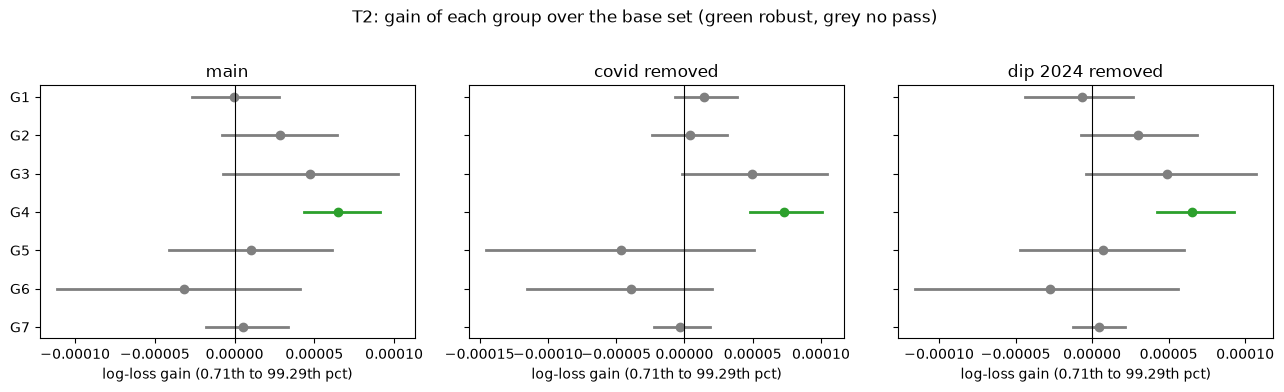

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
colors = {"robust": "#2ca02c", "fragile": "#ff7f0e", "no_pass": "#7f7f7f", "pass_main_only": "#1f77b4"}
groups = list(T2["verdicts"])[::-1]
for ax, scenario in zip(axes, SCENARIOS):
    part = t2[t2.scenario == scenario].set_index("group").loc[groups]
    for y, (group, r) in enumerate(part.iterrows()):
        color = colors[T2["verdicts"][group]]
        ax.plot([r.lower, r.upper], [y, y], color=color, lw=2)
        ax.plot(r.gain, y, "o", color=color)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(groups)), groups)
    ax.set_title(scenario.replace("_", " "))
    ax.set_xlabel("log-loss gain (0.71th to 99.29th pct)")
fig.suptitle("T2: gain of each group over the base set (green robust, grey no pass)", y=1.02)
plt.tight_layout()
plt.show()

The three runs side by side (lower end of each interval, and whether the group passed):

In [4]:
order = list(SCENARIOS)
lower = t2.pivot(index="group", columns="scenario", values="lower")[order].add_prefix("lower, ")
passed = t2.pivot(index="group", columns="scenario", values="passes")[order].add_prefix("passes, ")
lower.join(passed).join(pd.Series(T2["verdicts"], name="verdict")).round(7)

,"lower, main","lower, covid_removed","lower, dip_2024_removed","passes, main","passes, covid_removed","passes, dip_2024_removed",verdict
group,,,,,,,
G1,-0.000027,-0.000007,-0.000044,False,False,False,no_pass
G2,-0.000008,-0.000024,-0.000007,False,False,False,no_pass
G3,-0.000007,-0.000002,-0.000004,False,False,False,no_pass
G4,0.000044,0.000048,0.000043,True,True,True,robust
G5,-0.000041,-0.000145,-0.000047,False,False,False,no_pass
G6,-0.000111,-0.000115,-0.000116,False,False,False,no_pass
G7,-0.000018,-0.000022,-0.000012,False,False,False,no_pass


G4 is the only group whose lower end stays above zero in all three runs. G3 (segment history and pooling) is the nearest miss: a gain of about the same order, but its interval touches zero at this stricter percentile. G1, G2, G5 and G7 are statistically indistinguishable from zero, and G6 is slightly harmful.

## 3. How big is 'robust'?

In [5]:
g4 = main.loc["G4"]
print(f"G4: {g4.gain:.2e} on {g4.reference:.4f} = {g4.relative_pct:.3f}% of log-loss; "
      f"better in {int(g4.months_better)} of {int(g4.n_months)} test months")
print("Combined model tested:", T2["combined"])

G4: 6.50e-05 on 0.1127 = 0.058% of log-loss; better in 42 of 46 test months
Combined model tested: None


The direction is consistent (better in 42 of 46 months) and the size is a fraction of a tenth of a percent. The result reproduces the archived attempt's specialty-momentum figure (+6.5e-5) almost exactly, so it is not a fluke of one run. No combined model was tested, because only one group is robust.

## 4. T1: the national forecast

In [6]:
rows = []
for scenario, block in T1["scenarios"].items():
    for group, d in block["groups"].items():
        rows.append({
            "scenario": scenario, "group": group, "n_months": block["n_test_months"],
            "MAE": block["mae"]["ridge+" + group],
            "vs last month": d["against_last_month"]["estimate"],
            "lower (vs last month)": d["against_last_month"]["low"],
            "vs plain ridge": d["against_plain_ridge"]["estimate"],
            "passes": d["passes"],
        })
t1 = pd.DataFrame(rows)
m = T1["scenarios"]["main"]["mae"]
print("Main-run MAE (pp):", {k: round(v, 4) for k, v in m.items()})
print("Verdicts:", T1["verdicts"])
t1.round(4)

Main-run MAE (pp): {'last_month': 0.1246, 'ridge': 0.1466, 'ridge+G1': 0.1564, 'ridge+G2': 0.1644, 'ridge+G5': 0.1391, 'ridge+G6': 0.1641, 'ridge+G7': 0.1464}
Verdicts: {'G1': 'no_pass', 'G2': 'no_pass', 'G5': 'no_pass', 'G6': 'no_pass', 'G7': 'no_pass'}


,scenario,group,n_months,MAE,vs last month,lower (vs last month),vs plain ridge,passes
0,main,G1,48,0.1564,-0.0318,-0.0815,-0.0098,False
1,main,G2,48,0.1644,-0.0398,-0.0869,-0.0178,False
2,main,G5,48,0.1391,-0.0145,-0.0400,0.0075,False
3,main,G6,48,0.1641,-0.0396,-0.0901,-0.0175,False
4,main,G7,48,0.1464,-0.0219,-0.0532,0.0002,False
5,dip_2024_removed,G1,43,0.1486,-0.0255,-0.0705,-0.0036,False
6,dip_2024_removed,G2,43,0.1568,-0.0338,-0.0777,-0.0119,False
7,dip_2024_removed,G5,43,0.1379,-0.0148,-0.0433,0.0071,False
8,dip_2024_removed,G6,43,0.1445,-0.0214,-0.0462,0.0005,False
9,dip_2024_removed,G7,43,0.1475,-0.0245,-0.0620,-0.0026,False


Positive means the group lowered the error. Every ridge, with or without a group, is worse than "same as last month", in the main run and with the 2024 dip removed. Competitor volumes (G5) come closest and improve the plain ridge slightly, but not "same as last month".

## 5. Sensitivity: data through t-2 (not part of the pass rule)

In [7]:
s2 = SENS["t2"]["scenarios"]["main"]
rows = [{"group": g, "gain": d["estimate"], "lower": d["low"],
         "relative_pct": 100 * d["estimate"] / s2["reference_log_loss"],
         "months_better": f"{d['months_better']} / {s2['n_test_months']}", "passes": d["passes"]}
        for g, d in s2["groups"].items()]
print("rows scored:", s2["n_rows"], "| reference log-loss:", round(s2["reference_log_loss"], 5))
pd.DataFrame(rows).round({"gain": 7, "lower": 7, "relative_pct": 3})

rows scored: 8112 | reference log-loss: 0.1123


,group,gain,lower,relative_pct,months_better,passes
0,G1,0.000008,-0.000020,0.007,24 / 45,False
1,G2,0.000033,-0.000007,0.029,28 / 45,False
2,G3,0.000070,-0.000004,0.062,26 / 45,False
3,G4,0.000035,0.000022,0.031,38 / 45,True
4,G5,0.000079,0.000026,0.070,28 / 45,True
5,G6,-0.000023,-0.000104,-0.021,23 / 45,False
6,G7,0.000027,-0.000005,0.024,29 / 45,False


With a realistic two-month lag, G4 still passes. **G5 (competitor volumes) also passes here** (about +0.07%), which it did not in the main run. This is outside the pass rule and uses one scenario only, so it is a hypothesis for the modelling stage, not a finding. (The runner's printed summary labels both passes "robust" because this run has a single scenario; that label is a by-product.)

In [8]:
s1 = SENS["t1"]["scenarios"]["main"]
pd.DataFrame([{"group": g, "vs two-step baseline": d["against_last_month"]["estimate"],
               "lower": d["against_last_month"]["low"], "passes": d["passes"]}
              for g, d in s1["groups"].items()]).round(4)

,group,vs two-step baseline,lower,passes
0,G1,-0.0574,-0.1220,False
1,G2,-0.0446,-0.1057,False
2,G5,-0.0124,-0.0418,False
3,G6,-0.0371,-0.1060,False
4,G7,-0.0237,-0.0710,False


## 6. What we conclude

1. **One group earns its place for segment share:** specialty and market context (G4), about 0.06% of log-loss, robust to COVID and the 2024 dip.
2. **The two new ideas did not help in the main run:** competitor volumes (G5) and data-quality flags (G7). Outside signals (G6) are slightly harmful, which matches how heavily lagged they are.
3. **The national forecast does not improve with any group.** "Same as last month" stays the rule to beat.
4. **One hypothesis to carry forward:** competitor volumes under a *t-2* lag.

## Limits stated in the plan

- G2, G3 and G6 were EDA-informed: not a clean test.
- T1 has no COVID scenario (the COVID months precede the first test month); G7 cannot be tested by removal.
- The rule is a significance rule with no minimum effect size, so "robust" is not "worth a change".

A near-null result is a finding. The segment model is limited by the thin panel and the national series by its few independent months, not by a missing feature.